# Negativity bias in online reviews: analysis

Analysis for a preregistered study (https://doi.org/10.17605/OSF.IO/K9PMN) testing whether negative restaurant reviews receive more "useful" votes than positive ones, using a random sample of 50,000 reviews from the Yelp Open Dataset.

**Requirements:** Python 3 with pandas, matplotlib, scipy and statsmodels (`pip install pandas matplotlib scipy statsmodels`).

**Input:** `reviews_sample.csv`, created by `yelp_sample.py`. The Yelp data are not included in this repository, in line with Yelp's terms of use.

## 1. Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

pd.set_option("display.float_format", "{:.3f}".format)

## 2. Load data

In [2]:
df = pd.read_csv("reviews_sample.csv")
print(f"{len(df):,} reviews, {df.shape[1]} columns")
df.head()

50,000 reviews, 15 columns


,review_id,business_id,city,state,stars,star_group,useful,log_useful,funny,cool,date,year,review_age_days,word_count,exclamation_marks
0,1Aq0gvT2L05rFDZpd0UODQ,B3kpvT4oLJdQmU9lPnxdKA,Santa Barbara,CA,4,positive,1,0.693,1,1,2016-06-20,2016,2039,149,0
1,xjgCEhV3meQHedGO6F3bag,kbWKwvLXfJm5sLVfw-Foww,Santa Barbara,CA,5,positive,0,0.000,0,0,2019-05-17,2019,978,53,4
2,cyAx2DP6ciQSSvx3VOfETA,EyOva59wt7KBAhGknIcDlA,Eagleville,PA,4,positive,3,1.386,0,2,2012-11-27,2012,3340,77,0
3,BNKbTSZ4Iq2G7MMWLF3j4A,6djwQL1FOoe0SZONQHjhrw,Boise,ID,5,positive,0,0.000,0,0,2020-08-04,2020,533,44,1
4,xf1WMbXA6mQyFj0EMEB7wQ,Sv1MEZP-mMfp8SmE0hwYEA,Philadelphia,PA,4,positive,1,0.693,0,0,2019-09-25,2019,847,101,4


## 3. Missing values

In [3]:
df.isna().sum()

review_id            0
business_id          0
city                 0
state                0
stars                0
star_group           0
useful               0
log_useful           0
funny                0
cool                 0
date                 0
year                 0
review_age_days      0
word_count           0
exclamation_marks    0
dtype: int64

## 4. Descriptive statistics

In [4]:
main_vars = ["stars", "useful", "word_count", "review_age_days", "exclamation_marks"]
df[main_vars].describe().T

,count,mean,std,min,25%,50%,75%,max
stars,50000.000,3.796,1.391,1.000,3.000,4.000,5.000,5.000
useful,50000.000,0.994,2.628,0.000,0.000,0.000,1.000,147.000
word_count,50000.000,100.031,93.364,1.000,40.000,72.000,127.000,977.000
review_age_days,50000.000,1855.833,1128.387,0.000,990.000,1712.000,2572.250,6128.000
exclamation_marks,50000.000,1.313,2.363,0.000,0.000,0.000,2.000,131.000


## 5. Distribution of useful votes
Useful votes are strongly right-skewed (most reviews receive none), so the regression uses log(useful + 1) as the outcome.

58% of reviews got zero useful votes


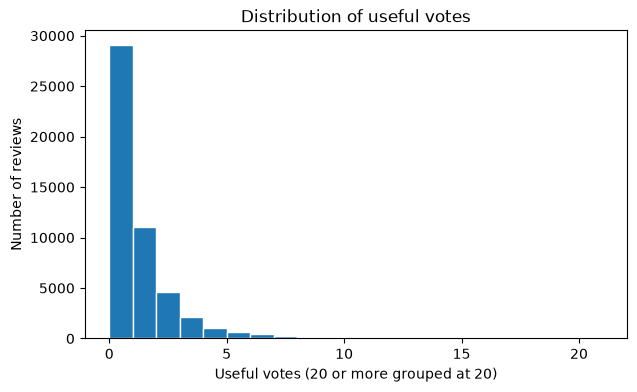

In [5]:
share_zero = (df["useful"] == 0).mean()
print(f"{share_zero:.0%} of reviews got zero useful votes")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df["useful"].clip(upper=20), bins=range(0, 22), edgecolor="white")
ax.set_xlabel("Useful votes (20 or more grouped at 20)")
ax.set_ylabel("Number of reviews")
ax.set_title("Distribution of useful votes")
plt.show()

## 6. Derived variables
Length in hundreds of words (`words100`), review age in years (`age_years`) and length bands for plotting.

In [6]:
df["words100"] = df["word_count"] / 100
df["age_years"] = df["review_age_days"] / 365
df["length_band"] = pd.cut(
    df["word_count"],
    bins=[0, 50, 150, 300, np.inf],
    labels=["0-50", "51-150", "151-300", "300+"],
    include_lowest=True,
)
df[["word_count", "words100", "review_age_days", "age_years", "length_band"]].head()

,word_count,words100,review_age_days,age_years,length_band
0,149,1.490,2039,5.586,51-150
1,53,0.530,978,2.679,51-150
2,77,0.770,3340,9.151,51-150
3,44,0.440,533,1.460,0-50
4,101,1.010,847,2.321,51-150


## 7. Useful votes by star rating (H1, descriptive)
Error bars show 95% confidence intervals.

,mean,median,count
stars,,,
1,1.119,0.000,5995
2,1.175,0.000,4270
3,1.070,0.000,5739
4,1.098,0.000,11949
5,0.848,0.000,22047


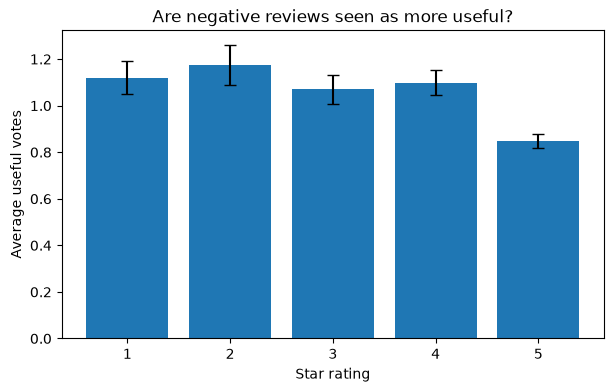

In [7]:
by_stars = df.groupby("stars")["useful"].agg(["mean", "median", "count", "sem"])
by_stars["ci95"] = 1.96 * by_stars["sem"]
display(by_stars[["mean", "median", "count"]])

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(by_stars.index, by_stars["mean"], yerr=by_stars["ci95"], capsize=4)
ax.set_xlabel("Star rating")
ax.set_ylabel("Average useful votes")
ax.set_title("Are negative reviews seen as more useful?")
fig.savefig("fig1_useful_by_stars.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Group comparison (H1)
Kruskal-Wallis test across star groups (non-parametric, as votes are skewed), followed by a Mann-Whitney U test of negative vs positive reviews with rank-biserial r as effect size. Given the large sample, effect sizes are interpreted alongside p-values.

In [8]:
order = ["negative", "neutral", "positive"]
display(df.groupby("star_group")["useful"].agg(["mean", "median", "count"]).reindex(order))

groups = [df.loc[df["star_group"] == g, "useful"] for g in order]
H, p_kw = stats.kruskal(*groups)
n, k = len(df), len(groups)
eta2_H = (H - k + 1) / (n - k)
print(f"Kruskal-Wallis: H({k-1}) = {H:.2f}, p = {p_kw:.3g}, eta-squared(H) = {eta2_H:.3f}")

neg = df.loc[df["star_group"] == "negative", "useful"]
pos = df.loc[df["star_group"] == "positive", "useful"]
U, p_mw = stats.mannwhitneyu(neg, pos, alternative="two-sided")
r_rb = 2 * U / (len(neg) * len(pos)) - 1
print(f"Negative vs positive: U = {U:,.0f}, p = {p_mw:.3g}, rank-biserial r = {r_rb:.3f}")
print("(positive r = negative reviews tend to get MORE useful votes)")

,mean,median,count
star_group,,,
negative,1.142,0.000,10265
neutral,1.070,0.000,5739
positive,0.936,0.000,33996


Kruskal-Wallis: H(2) = 268.69, p = 4.52e-59, eta-squared(H) = 0.005
Negative vs positive: U = 190,240,426, p = 3.92e-55, rank-biserial r = 0.090
(positive r = negative reviews tend to get MORE useful votes)


## 9. Regression (H1–H3)
OLS regression of log(useful + 1) on star group (reference: positive), length, length², review age and exclamation marks, with heteroscedasticity-robust (HC3) standard errors.

Preregistered predictions: H1, negative coefficient > 0; H2, length > 0 and length² < 0; H3, exclamation marks < 0.

In [9]:
formula = (
    "log_useful ~ C(star_group, Treatment('positive'))"
    " + words100 + I(words100 ** 2) + age_years + exclamation_marks"
)
model = smf.ols(formula, data=df).fit(cov_type="HC3")
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             log_useful   R-squared:                       0.151
Model:                            OLS   Adj. R-squared:                  0.151
Method:                 Least Squares   F-statistic:                     1058.
Date:                Mon, 23 Nov 2026   Prob (F-statistic):               0.00
Time:                        11:40:45   Log-Likelihood:                -41710.
No. Observations:               50000   AIC:                         8.343e+04
Df Residuals:                   49993   BIC:                         8.350e+04
Df Model:                           6                                         
Covariance Type:                  HC3                                         
                                                       coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------

## 10. Interpretation of coefficients
With a log outcome, a coefficient b corresponds to an approximate (e^b − 1) × 100% change in (useful votes + 1).

In [10]:
b = model.params
neg_key = "C(star_group, Treatment('positive'))[T.negative]"
neu_key = "C(star_group, Treatment('positive'))[T.neutral]"

for label, key in [("Negative", neg_key), ("Neutral", neu_key)]:
    change = (np.exp(b[key]) - 1) * 100
    print(f"{label} reviews: about {change:+.1f}% useful votes (+1) compared with positive reviews, holding length, age and '!' constant.")

if b["I(words100 ** 2)"] < 0:
    peak = -b["words100"] / (2 * b["I(words100 ** 2)"]) * 100
    print(f"Length: usefulness peaks at roughly {peak:.0f} words, then declines.")
else:
    print("Length: no peak found; usefulness keeps rising (or falling) with length.")

excl = (np.exp(b["exclamation_marks"]) - 1) * 100
print(f"Each extra '!': about {excl:+.1f}% useful votes (+1).")
print(f"R-squared: {model.rsquared:.3f} -> the model explains {model.rsquared:.1%} of the differences in usefulness.")

Negative reviews: about +1.6% useful votes (+1) compared with positive reviews, holding length, age and '!' constant.
Neutral reviews: about -3.3% useful votes (+1) compared with positive reviews, holding length, age and '!' constant.
Length: usefulness peaks at roughly 643 words, then declines.
Each extra '!': about +0.2% useful votes (+1).
R-squared: 0.151 -> the model explains 15.1% of the differences in usefulness.


## 11. Useful votes by review length (H2)

,mean,count
length_band,,
0-50,0.412,17335
51-150,0.909,23071
151-300,1.953,7574
300+,3.366,2020


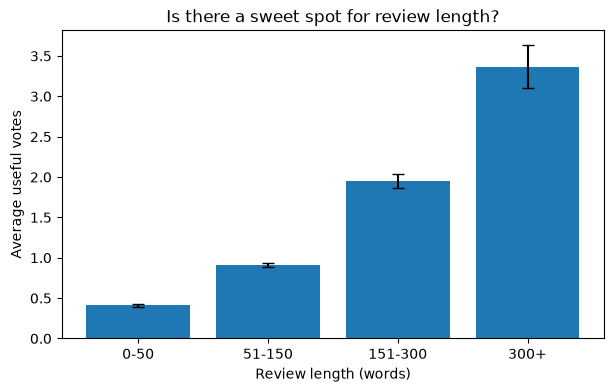

In [11]:
by_len = df.groupby("length_band", observed=True)["useful"].agg(["mean", "count", "sem"])
by_len["ci95"] = 1.96 * by_len["sem"]
display(by_len[["mean", "count"]])

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(by_len.index.astype(str), by_len["mean"], yerr=by_len["ci95"], capsize=4)
ax.set_xlabel("Review length (words)")
ax.set_ylabel("Average useful votes")
ax.set_title("Is there a sweet spot for review length?")
fig.savefig("fig2_useful_by_length.png", dpi=200, bbox_inches="tight")
plt.show()

## 12. Exclamation marks and usefulness (H3, bivariate)

In [12]:
rho, p_rho = stats.spearmanr(df["exclamation_marks"], df["useful"])
print(f"Spearman rho = {rho:.3f}, p = {p_rho:.3g}")

Spearman rho = 0.046, p = 5.56e-25


## 13. Export results

In [13]:
summary = pd.DataFrame({
    "statistic": [
        "N reviews", "Share with zero useful votes",
        "Kruskal-Wallis H", "Kruskal-Wallis p", "eta-squared(H)",
        "Mann-Whitney rank-biserial r (neg vs pos)",
        "Regression R-squared",
    ],
    "value": [len(df), share_zero, H, p_kw, eta2_H, r_rb, model.rsquared],
})
summary.to_csv("results_summary.csv", index=False)
model.params.to_frame("coef").join(model.pvalues.to_frame("p")).to_csv("regression_coefficients.csv")
summary

,statistic,value
0,N reviews,50000.000
1,Share with zero useful votes,0.581
2,Kruskal-Wallis H,268.690
3,Kruskal-Wallis p,0.000
4,eta-squared(H),0.005
5,Mann-Whitney rank-biserial r (neg vs pos),0.090
6,Regression R-squared,0.151
